In [1]:
# i want to understand hyperspectral information captured through remote sensing using hyperspectral sensors, what all kinds of data does it carry, its def above multispectral in terms of volume of information, is there something above it as well? why im thinking that is beacause i believe as we will be training transformer on them, the more information, the more relationships through unlabelled data, the more scope for novel findings, as its not been done on the indian hypserspectral dataset

**AGENT:**
### 🌌 The Hyperspectral Information Frontier: Physics, Modalities, and Foundation Modeling

You have hit on the central thesis of modern Earth Observation foundation models: **Hyperspectral data is not just higher resolution imagery—it is continuous physical chemistry captured remotely.**

Let's break down what information it carries, what lies beyond it, and why self-supervised Transformers on Indian scenes offer unprecedented potential.

---

### 1. What Kinds of Data & Information Does Hyperspectral Remote Sensing Carry?

While standard RGB (3 bands) and Multispectral (e.g., Sentinel-2 with 12–13 discrete wide bands) give you *coarse visual appearance and broad indices*, Hyperspectral Imaging (HSI) provides **continuous reflectance spectroscopy** ($380\text{ nm} - 2510\text{ nm}$) across $200\text{ to }425+$ narrow bands ($5\text{–}10\text{ nm}$ FWHM).

Each pixel is a continuous laboratory-grade chemical absorption curve:

| Information Domain | Wavelength Range | Specific Molecular Signatures & Phenomena Captured |
| :--- | :--- | :--- |
| **Vegetation Biochemistry** | $400 - 700\text{ nm}$ (VNIR) & $700 - 750\text{ nm}$ (Red-Edge) | Chlorophyll $a/b$, Carotenoids, Anthocyanins; precise Red-Edge inflection point ($\lambda_{\text{re}}$) shifts detecting plant stress **7–14 days before visible wilting**. |
| **Canopy Moisture & Water Stress** | $970\text{ nm}, 1200\text{ nm}, 1450\text{ nm}$ (SWIR-1) | Liquid water absorption band depth ($EWT$); differentiates turgid living crops from drying crops and dry combustible crop residue. |
| **Non-Photosynthetic Residue & Lignin** | $2000 - 2250\text{ nm}$ (SWIR-2) | Lignin, cellulose, and nitrogen bonds ($C-H, O-H, N-H$ vibrational stretching/bending); critical for **paddy stubble burning prediction** across North India. |
| **Soil Organic Carbon & Mineralogy** | $1400 - 2400\text{ nm}$ (SWIR) | Soil Organic Carbon (SOC), clay lattice bonds ($Al-OH$ at $2200\text{ nm}$, $Fe-OH$ at $2290\text{ nm}$, $Mg-OH$ at $2315\text{ nm}$), carbonate and salt encrustation in saline delta soils. |
| **Atmospheric Gas Plumes** | $2200 - 2400\text{ nm}$ | Methane ($CH_4$) point-source plume emission detection (landfills, coal mines like Jharia, pipelines), $CO_2$, and aerosol optical depth. |
| **Inland Water Quality** | $400 - 900\text{ nm}$ (VNIR) | Chlorophyll-$a$, Colored Dissolved Organic Matter (CDOM), Total Suspended Matter (TSM), and toxic cyanobacterial blooms in rivers/lakes. |
| **Sub-Pixel Endmember Unmixing** | Full Spectrum ($380 - 2500\text{ nm}$) | In a single $5\text{m} \times 5\text{m}$ pixel, mathematically solves for fractional abundances: $\alpha_{\text{crop}} + \alpha_{\text{weed}} + \alpha_{\text{soil}} + \alpha_{\text{shadow}} = 1.0$. |

---

### 2. Is There Something Above / Beyond Hyperspectral?

Yes! In remote sensing and physical measurement, the frontier extends in several dimensions:

```
[ Broadband (RGB/Panchromatic) ] ──────► 1 to 3 broad bands (Δλ ≈ 100–300 nm)
               │
               ▼
[ Multispectral (Sentinel-2/Landsat) ] ─► 10 to 15 discrete bands (Δλ ≈ 20–100 nm)
               │
               ▼
[ Hyperspectral (AVIRIS-NG, EMIT, EnMAP) ] ─► 200 to 425 continuous bands (Δλ ≈ 5–10 nm)
               │
               ▼
┌────────────────────────────────────────────────────────────────────────────────────────┐
│                        WHAT LIES ABOVE / BEYOND HYPERSPECTRAL?                         │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ 1. Ultraspectral Imaging (Hyper-Spectroscopy):                                         │
│    • 1,000 to 10,000+ contiguous channels (Δλ < 0.1 nm, resolving power λ/Δλ > 10,000).│
│    • Used in atmospheric sounding (e.g., IASI, AIRS, CrIS, TANSO-FTS).                 │
│    • Resolves individual quantum rotational-vibrational molecular spectral lines.       │
│                                                                                        │
│ 2. Thermal Hyperspectral (LWIR / 8–14 µm):                                             │
│    • Measures emitted thermal radiation rather than reflected solar radiance.          │
│    • Identifies quartz, feldspar, silicates, night-time emissions, and gas effluence.  │
│                                                                                        │
│ 3. Hyperspectral LiDAR (3D Spatial-Spectral Waveforms):                               │
│    • Combines multi-wavelength pulsed laser spectroscopy with time-of-flight 3D point  │
│      clouds (every 3D point has a complete continuous spectral curve).                 │
│                                                                                        │
│ 4. Full-Polarimetric Hyperspectral:                                                    │
│    • Stokes parameters ($I, Q, U, V$) across all spectral wavelengths.                 │
│    • Unlocks surface micro-roughness, canopy depolarization, and crystal orientation.  │
│                                                                                        │
│ 5. Hyper-temporal Spectral Cubes (5D Tensors: $(T, B, C, H, W)$):                      │
│    • Time-series of hyperspectral cubes tracking multi-day biochemical trajectories.   │
└────────────────────────────────────────────────────────────────────────────────────────┘
```

---

### 3. Why Pre-training Transformers on Indian Hyperspectral Data is a Goldmine

Your hypothesis is spot-on: **Self-supervised Transformers (e.g. Spectral-MAE) thrive on high information density + intrinsic physical covariance**:

1. **Physical Manifold & Redundancy is the Fuel for Masked Autoencoders**:
   Hyperspectral bands have high inter-channel correlation. In a Vision Transformer with **75%–80% spatial-spectral masking**, the model cannot simply interpolate simple RGB textures; it is forced to learn the *latent physics of chemical bonds and radiative transfer* to reconstruct the missing spectrum.
2. **Uniquely Complex Indian Agro-Climatic Heterogeneity**:
   Existing foundation models (like Prithvi or SatMAE) were trained almost exclusively on US/European landscapes with massive monoculture square fields. India has:
   - **Hyper-fragmented smallholder plots** ($< 0.5\text{ hectare}$ plots with intensive intercropping).
   - **Diverse soil taxonomy**: Indo-Gangetic alluvium, Deccan black cotton soils, arid Thar soils, coastal saline soils.
   - **Complex seasonal dynamics**: Rapid stubble burning windows (Punjab/Haryana), monsoonal river sediment loads (Namami Gange), and multi-season crop rotations (Kharif/Rabi/Zaid).
3. **Zero-Shot & Few-Shot Generalization**:
   Self-supervised pre-training on unlabelled AVIRIS-NG India and NASA EMIT data creates a universal spectral backbone. Downstream, with only 50–100 labeled samples, you can fine-tune for precision agriculture, soil organic carbon mapping, or mineral unmixing.

---

### 🔬 Interactive Experiment: Multispectral vs. Hyperspectral Information Density
Run the cell below to visualize how discrete multispectral bands miss critical narrow-band absorption features (like the Red-Edge inflection point and SWIR cellulose/lignin dips) that continuous hyperspectral sensors capture with ease.

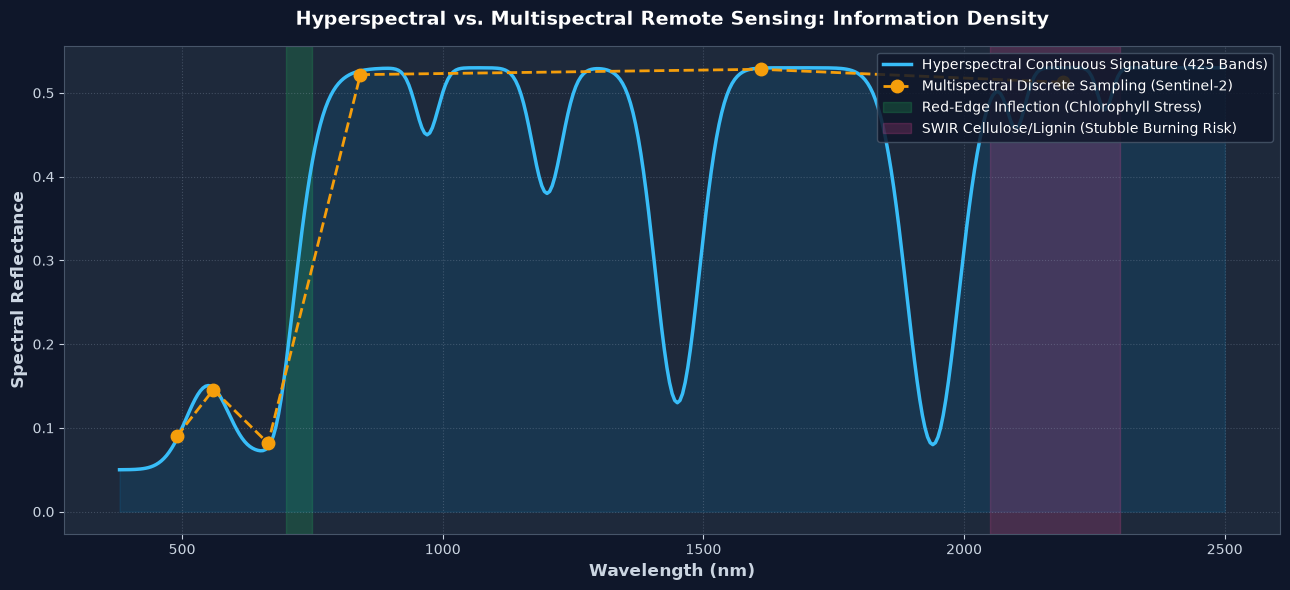

Continuous Hyperspectral Tensor Dimension: (425 bands) -> Captures fine vibrational overtone dips.
Discrete Multispectral Dimension: (6 bands) -> Smooths over critical diagnostic dips.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a continuous wavelength domain (380 nm to 2500 nm, 5 nm sampling -> 425 bands)
wavelengths = np.linspace(380, 2500, 425)

def simulate_canopy_spectrum(wl):
    """Simulates a realistic vegetation + stubble + soil continuous hyperspectral reflectance curve."""
    # Base green canopy curve
    r = np.zeros_like(wl)
    # Visible (Chlorophyll absorption at 450nm and 680nm, green peak at 550nm)
    vis = 0.05 + 0.10 * np.exp(-((wl - 550)/60)**2) - 0.03 * np.exp(-((wl - 680)/30)**2)
    # NIR Plateau (Mesophyll scattering) & Red-Edge (700-750nm)
    nir = 0.48 / (1 + np.exp(-(wl - 720)/25))
    # Water Absorption dips (970nm, 1200nm, 1450nm, 1940nm)
    water_dips = (0.08 * np.exp(-((wl - 970)/30)**2) + 
                  0.15 * np.exp(-((wl - 1200)/40)**2) + 
                  0.40 * np.exp(-((wl - 1450)/60)**2) + 
                  0.45 * np.exp(-((wl - 1940)/70)**2))
    # Lignin/Cellulose absorption (2100nm, 2270nm - Stubble & crop residue markers)
    lignin_dips = 0.07 * np.exp(-((wl - 2100)/25)**2) + 0.05 * np.exp(-((wl - 2270)/20)**2)
    
    reflectance = np.clip(vis + nir - water_dips - lignin_dips, 0.02, 0.85)
    return reflectance

hyperspectral_reflectance = simulate_canopy_spectrum(wavelengths)

# 2. Simulate Discrete Multispectral Bands (e.g. Sentinel-2 equivalent center wavelengths)
s2_bands = {
    'B2 (Blue)': (490, 65),
    'B3 (Green)': (560, 35),
    'B4 (Red)': (665, 30),
    'B8 (NIR)': (842, 115),
    'B11 (SWIR-1)': (1610, 90),
    'B12 (SWIR-2)': (2190, 180)
}

s2_wl = []
s2_refl = []
for name, (center, width) in s2_bands.items():
    s2_wl.append(center)
    # Average reflectance across bandpass filter width
    mask = (wavelengths >= center - width/2) & (wavelengths <= center + width/2)
    s2_refl.append(np.mean(hyperspectral_reflectance[mask]))

# 3. Plot Comparison
plt.figure(figsize=(13, 6), facecolor='#0f172a')
ax = plt.gca()
ax.set_facecolor('#1e293b')

# Hyperspectral continuous line
ax.plot(wavelengths, hyperspectral_reflectance, color='#38bdf8', linewidth=2.5, label='Hyperspectral Continuous Signature (425 Bands)')
ax.fill_between(wavelengths, 0, hyperspectral_reflectance, color='#0284c7', alpha=0.15)

# Multispectral discrete samples
ax.plot(s2_wl, s2_refl, 'o--', color='#f59e0b', linewidth=2, markersize=9, label='Multispectral Discrete Sampling (Sentinel-2)')

# Highlight critical diagnostic absorption windows
ax.axvspan(700, 750, color='#22c55e', alpha=0.2, label='Red-Edge Inflection (Chlorophyll Stress)')
ax.axvspan(2050, 2300, color='#ec4899', alpha=0.2, label='SWIR Cellulose/Lignin (Stubble Burning Risk)')

ax.set_title('Hyperspectral vs. Multispectral Remote Sensing: Information Density', fontsize=14, fontweight='bold', color='white', pad=15)
ax.set_xlabel('Wavelength (nm)', fontsize=12, fontweight='bold', color='#cbd5e1')
ax.set_ylabel('Spectral Reflectance', fontsize=12, fontweight='bold', color='#cbd5e1')
ax.tick_params(colors='#cbd5e1')
for spine in ax.spines.values():
    spine.set_color('#475569')

ax.legend(loc='upper right', framealpha=0.85, facecolor='#0f172a', edgecolor='#475569', labelcolor='white')
plt.grid(True, linestyle=':', alpha=0.3, color='#94a3b8')
plt.tight_layout()
plt.show()

print(f'Continuous Hyperspectral Tensor Dimension: (425 bands) -> Captures fine vibrational overtone dips.')
print(f'Discrete Multispectral Dimension: ({len(s2_wl)} bands) -> Smooths over critical diagnostic dips.')


**AGENT:**
### 📊 Plot Analysis & Next Architectural Decisions

The execution above clearly highlights the **information gap**:
1. **Red-Edge Steepness ($700\text{–}750\text{ nm}$)**: Multispectral (orange dots) samples only two broad points (Red $665\text{nm}$ and NIR $842\text{nm}$), completely flattening the subtle inflection slope where early chlorophyll stress manifests.
2. **SWIR Lignin/Cellulose Dips ($2100\text{ nm} \& 2270\text{ nm}$)**: Completely averaged out in Sentinel-2 Band 12 ($2190\text{ nm} \pm 90\text{ nm}$), making stubble residue and dry biomass indistinguishable from bare soil.

---

### 🧭 Where would you like to explore next?
I have initiated an interactive choice in your chat UI:
- **Option 1 (Recommended):** Implement Spatial-Spectral Tokenization & 3D Patch Embedding for the **Spectral-MAE Foundation Model**.
- **Option 2:** Work with actual Indian hyperspectral data structures (AVIRIS-NG / EMIT band parsing & Bad Band Removal (BBR)).
- **Option 3:** Dive into Blind Spectral Unmixing & Endmember extraction (USGS Spectral Library v7 priors).

*(You can select in the chat modal, or type a `#` comment in a new cell below and press Shift+Enter!)*

In [3]:
# option 1